In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.utils.prune as prune
from torchvision.models.resnet import ResNet, BasicBlock
import copy
from torchvision.models import resnet18
from torchvision.models.quantization import resnet18 as q_resnet18
import pandas as pd
from tqdm import tqdm #I like when it looks pretty
import time
import os
import gzip 

SAVE_DIR = (
    r"C:\Users\hoodo\Desktop\universitas\bachelor\BACHELORfinal"
    if os.name == "nt"
    else "/mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELORfinal"
)
os.makedirs(SAVE_DIR, exist_ok=True)

device ='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [8]:

### DATA LOADING ###
batch_size=128
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

trainSet = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
train_subset, val_subset = torch.utils.data.random_split(trainSet, [42500, 7500], generator=torch.Generator().manual_seed(1))
testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

trainLoader = torch.utils.data.DataLoader(trainSet, batch_size=batch_size, shuffle=True, num_workers=2)
validLoader = torch.utils.data.DataLoader(val_subset, batch_size=batch_size, shuffle=True, num_workers=2)
testLoader = torch.utils.data.DataLoader(testSet, batch_size=batch_size, shuffle=False, num_workers=2)
    



/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [9]:
#HELPERS

###this is just to keep the helpers in one place, I'll define them as I go

def print_size_of_model(model, returning=False):
    
    torch.save(model.state_dict(), "temp.p")
    
    #solution to a past issue achieved with a generative model here, unfortunately
    #I'm compressing the temporarily saved model to accurately reflect the effect of pruning
    with open("temp.p", "rb") as f_in:
        with gzip.open("temp.p.gz", "wb") as f_out:
            f_out.writelines(f_in)
    size = os.path.getsize("temp.p.gz") / 1e6
    print('Size (MB):', size)
    os.remove("temp.p")
    os.remove("temp.p.gz")  
    if returning: return size


In [10]:
#BASELINE CLASSIFIER DEFINITION/TRAINING
baseline_model = resnet18(num_classes=10)
baseline_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False) # inspired by the github example: this is to avoid downsampling the already small images from CIFAR10 too quickly
baseline_model.maxpool = nn.Identity() 


In [11]:

def train_baseline(model, train_loader, val_loader, epochs=20):
    
    model.to(device)
    
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    #I used to have these outside the function, hence the "bl" at the end to differentiate, but I realized that it may have been stupid
    optimizer_bl = optim.Adam(model.parameters(), lr=1e-3, weight_decay=0.000125)
    criterion_bl = nn.CrossEntropyLoss()
    lr_scheduler_bl = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_bl, T_max=200)


    #train phase
    for epoch in range(epochs):
        print(f'epoch = {epoch}')
        model.train()
        running_loss = 0.0
        
        for inputs, labels in tqdm(train_loader, desc=f"Training, epoch: [{epoch+1}/{epochs}]"):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer_bl.zero_grad() #clear grads
            outputs = model(inputs) #forward pass
            loss = criterion_bl(outputs, labels) 
            loss.backward() #grads
            optimizer_bl.step() #update

            running_loss += loss.item()
            
        lr_scheduler_bl.step()

        #validation
        model.eval() 
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc=f"Val, epoch: [{epoch+1}/{epochs}]"):
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_acc = 100 * correct / total
        avg_loss = running_loss / len(train_loader)
        
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {avg_loss:.4f} | Val Acc: {val_acc:.2f}%")

        #saving best model:
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'resnet18_best.pth'))

    print(f"Done. Best val accuracy: {best_acc:.2f}%")
    
    #this is to load best weights into model before returning:
    model.load_state_dict(best_model_wts)
    return model

In [12]:
trained_model = train_baseline(baseline_model, trainLoader, validLoader, epochs=20) 


epoch = 0


Training, epoch: [1/20]:   0%|                                                                  | 0/391 [00:00<?, ?it/s]

Val, epoch: [1/20]: 100%|██████████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 130.76it/s]


Epoch [1/20] Loss: 1.3350 | Val Acc: 60.91%
epoch = 1


Val, epoch: [2/20]: 100%|██████████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 133.17it/s]


...

Epoch [18/20] Loss: 0.2464 | Val Acc: 90.87%
epoch = 18


Val, epoch: [19/20]: 100%|█████████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 130.62it/s]


Epoch [19/20] Loss: 0.2372 | Val Acc: 90.99%
epoch = 19


Val, epoch: [20/20]: 100%|█████████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 141.01it/s]


Epoch [20/20] Loss: 0.2267 | Val Acc: 91.04%
Done. Best val accuracy: 91.04%


In [13]:
#This is so I don't have to retrain baseline a billion times in the future

trained_baseline = baseline_model
trained_baseline.load_state_dict(torch.load(os.path.join(SAVE_DIR, 'resnet18_best.pth'), weights_only=True))

<All keys matched successfully>

For my student model, I will take a ResNet18 and remove the 4th stage, ending up with a student model ~4 times smaller than the teacher (~3 million parameters vs ~11.7 million). Without the 4th stage, it basically loses 4 layers, so naturally it becomes ResNet14, and that's what I will call it.

In [14]:

class Resnet14(ResNet):
    def __init__(self, num_classes=10):
        #dummy config
        super().__init__(BasicBlock,[2, 2, 2, 2], num_classes=num_classes)
        
        del self.layer4 
        
        self.fc = nn.Linear(256 * BasicBlock.expansion, num_classes)

    def _forward_impl(self, x):
        # Re-write the forward pass to skip layer4
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        # Skip layer 4 entirely

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

# Test it
model = Resnet14(num_classes=1000)
params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {params / 1e6:.2f} M") # Outputs: 3.03 M

Total Parameters: 3.04 M


In [15]:
resnet14 = Resnet14()


For knowledge distillation, I referred to the pytorch tutorial: https://docs.pytorch.org/tutorials/beginner/knowledge_distillation_tutorial.html

In [16]:
def train_knowledge_distillation(teacher, student, train_loader, val_loader, epochs=20, T=2.0, soft_target_loss_weight=0.75, ce_loss_weight=0.25, saveAs='student_distilled_best.pth'):
    
    teacher.to(device)
    student.to(device)
    
    teacher.eval()  # teacher is ONLY in eval mode, it is NOT being trained
    student.train() 

    optimizer_sm = optim.Adam(student.parameters(), lr=1e-3, weight_decay=0.000125)
    lr_scheduler_sm = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_sm, T_max=200)

    kl_div_loss = nn.KLDivLoss(reduction='batchmean') #KL divergence loss
    #p.s. it was manually defined in the tutorial but I found this implementation and decided to use it instead
    
    best_acc = 0.0
    
    for epoch in range(epochs):
        running_loss = 0.0
        load = tqdm(train_loader, desc=f"Distilling Epoch [{epoch+1}/{epochs}]")
        for inputs, labels in load:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer_sm.zero_grad()

            # (gradients not saved, we do not change teacher's weights)
            with torch.no_grad():
                teacher_logits = teacher(inputs)

            student_logits = student(inputs)

            # softening logits with softmax and log
            # temperature T softens the probability distribution to reveal "dark knowledge"
            soft_targets = F.softmax(teacher_logits / T, dim=-1)
            soft_prob = F.log_softmax(student_logits / T, dim=-1)
            
            # Calculate JUST the soft targets loss. Scaled by T**2 as suggested by the authors of the paper "Distilling the knowledge in a neural network"
            soft_targets_loss = kl_div_loss(soft_prob, soft_targets) * (T**2)
            

            # JUST the true label loss
            label_loss = F.cross_entropy(student_logits, labels)

            # actual loss (weighted sum of two losses)
            loss = (soft_target_loss_weight * soft_targets_loss) + (ce_loss_weight * label_loss)
            
            loss.backward()
            optimizer_sm.step()

            running_loss += loss.item()
            load.set_postfix(loss=loss.item())
        
        lr_scheduler_sm.step()

        # validation
        student.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc=f"Distilling Epoch [{epoch+1}/{epochs}]"):
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = student(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        val_acc = 100 * correct / total
        print(f"Epoch {epoch+1} | Distillation Loss: {running_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2f}%")
        
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(student.state_dict(), saveAs)
            
        student.train()

    return student

In [17]:
trained_resnet14 = train_knowledge_distillation(teacher=trained_baseline, student=resnet14, train_loader=trainLoader, val_loader=validLoader, epochs=50, T=4.0, soft_target_loss_weight=0.9, ce_loss_weight=0.1, saveAs=os.path.join(SAVE_DIR, "big_student_distilled_best.pth"))


Distilling Epoch [1/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 155.28it/s]


Epoch 1 | Distillation Loss: 5.6015 | Val Acc: 58.20%


Distilling Epoch [2/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 145.21it/s]


Epoch 2 | Distillation Loss: 3.6614 | Val Acc: 62.97%


Distilling Epoch [3/50]: 100%|█████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 146.78it/s]


...

Epoch 48 | Distillation Loss: 0.8686 | Val Acc: 85.32%


Distilling Epoch [49/50]: 100%|████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 155.29it/s]


Epoch 49 | Distillation Loss: 0.8565 | Val Acc: 86.19%


Distilling Epoch [50/50]: 100%|████████████████████████████████████████████████████████| 59/59 [00:00<00:00, 157.61it/s]


Epoch 50 | Distillation Loss: 0.8681 | Val Acc: 87.19%


In [18]:
#just for loading 
trained_resnet14 = Resnet14()
trained_resnet14.load_state_dict(torch.load(os.path.join(SAVE_DIR, 'big_student_distilled_best.pth'), weights_only=True))

<All keys matched successfully>

In [19]:
# COMPARISON/EVAL/REPORT

def measure_inference_latency(model, loader, device):
    model.to(device)
    model.eval()
    start_time = time.time()
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            _ = model(inputs)
    end_time = time.time()
    avg_time = (end_time - start_time) / len(loader)
    return avg_time * 1000 #ms

def evaluate_accuracy(model, loader, device):
    model.to(device)
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

In [20]:
baseline_eval = copy.deepcopy(baseline_model)
baseline_eval.load_state_dict(torch.load('resnet18_best.pth', map_location='cpu'))

models_to_test = {
    "Baseline": baseline_eval,
    "ResNet14": trained_resnet14,
}

results = []

print(f"{'Model':<20} | {'Size (MB)':<10} | {'Acc (%)':<10} | {'Latency (ms)':<10}")
print("-" * 60)

for name, model in models_to_test.items():
    eval_device = 'cpu' 
    
    size = print_size_of_model(model, True)
    acc = evaluate_accuracy(model, testLoader, eval_device)
    lat = measure_inference_latency(model, testLoader, eval_device)
    
    print(f"{name:<20} | {size:<10.2f} | {acc:<10.2f} | {lat:<10.2f}")
    
    results.append({
        "Model": name,
        "Size (MB)": size,
        "Accuracy (%)": acc,
        "Latency (ms)": lat
    })

df = pd.DataFrame(results)
df.to_csv("stage1_results.csv", index=False)
df

Model                | Size (MB)  | Acc (%)    | Latency (ms)
------------------------------------------------------------
Size (MB): 35.006767
Baseline             | 35.01      | 88.79      | 147.18    
Size (MB): 9.18125
ResNet14             | 9.18       | 85.49      | 11.75     


,Model,Size (MB),Accuracy (%),Latency (ms)
0,Baseline,35.006767,88.79,147.184432
1,ResNet14,9.181250,85.49,11.753610


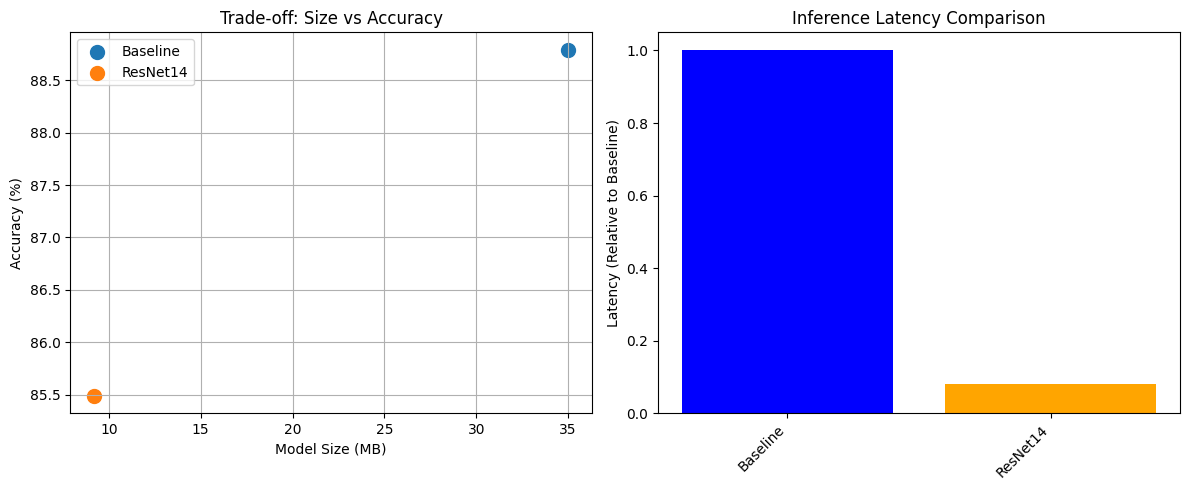

In [21]:
import matplotlib.pyplot as plt

def plot_results(df):
    plt.figure(figsize=(12, 5))

    # size vs accuracy
    plt.subplot(1, 2, 1)
    for i, row in df.iterrows():
        plt.scatter(row['Size (MB)'], row['Accuracy (%)'], label=row['Model'], s=100)
        
    plt.xlabel('Model Size (MB)')
    plt.ylabel('Accuracy (%)')
    plt.title('Trade-off: Size vs Accuracy')
    plt.legend()
    plt.grid(True)

    # latency bar chart (normalized)
    plt.subplot(1, 2, 2)
    baseline_lat = df[df['Model'] == 'Baseline']['Latency (ms)'].values[0]
    df['Rel Latency'] = df['Latency (ms)'] / baseline_lat
    
    colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
    plt.bar(df['Model'], df['Rel Latency'], color=colors)
    plt.ylabel('Latency (Relative to Baseline)')
    plt.title('Inference Latency Comparison')
    plt.xticks(rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig("compression_analysis.png")
    plt.show()

plot_results(df)